In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("cleaned_sales_dataset.csv")

In [ ]:
# Display first 5 records
display(df.head())

# Check dataset dimensions
print("Shape:", df.shape)

# Display column names
print("Columns:", df.columns.tolist())

# Check data types and non-null counts
df.info()

,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales
0,ORD100002,2025-02-25,CUST5529,Customer_227,30.0,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39
1,ORD100003,2025-10-14,CUST3127,Customer_182,63.0,Male,Bengaluru,Book,Education,5,27906.16,139530.80
2,ORD100004,2025-05-13,CUST8887,Customer_487,62.0,Female,Bengaluru,Book,Education,8,37491.06,299928.48
3,ORD100005,2025-12-02,CUST2515,Customer_470,65.0,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24
4,ORD100006,2025-11-20,CUST4796,Customer_380,44.0,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90


Shape: (1000, 12)
Columns: ['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'Age', 'Gender', 'City', 'Product', 'Category', 'Quantity', 'Unit_Price', 'Total_Sales']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order_ID       1000 non-null   object 
 1   Order_Date     1000 non-null   object 
 2   Customer_ID    1000 non-null   object 
 3   Customer_Name  1000 non-null   object 
 4   Age            1000 non-null   float64
 5   Gender         1000 non-null   object 
 6   City           1000 non-null   object 
 7   Product        1000 non-null   object 
 8   Category       1000 non-null   object 
 9   Quantity       1000 non-null   int64  
 10  Unit_Price     1000 non-null   float64
 11  Total_Sales    1000 non-null   float64
dtypes: float64(3), int64(1), object(8)
memory usage: 93.9+ KB


In [ ]:
# Separate numerical and categorical columns

numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns

categorical_cols = df.select_dtypes(include=['object']).columns

print("Numerical Columns:")
print(numerical_cols.tolist())

print("\nCategorical Columns:")
print(categorical_cols.tolist())

Numerical Columns:
['Age', 'Quantity', 'Unit_Price', 'Total_Sales']

Categorical Columns:
['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'Gender', 'City', 'Product', 'Category']


In [ ]:
# Generate descriptive statistics for numerical columns

df[numerical_cols].describe()

,Age,Quantity,Unit_Price,Total_Sales
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,41.353000,5.435000,25486.783410,139399.439650
std,13.683626,2.838632,14179.402361,114100.051546
min,18.000000,1.000000,145.780000,437.340000
25%,30.000000,3.000000,13895.722500,47066.632500
50%,41.000000,5.000000,25398.740000,108594.025000
75%,53.000000,8.000000,37512.382500,203722.882500
max,65.000000,10.000000,49997.530000,493677.500000


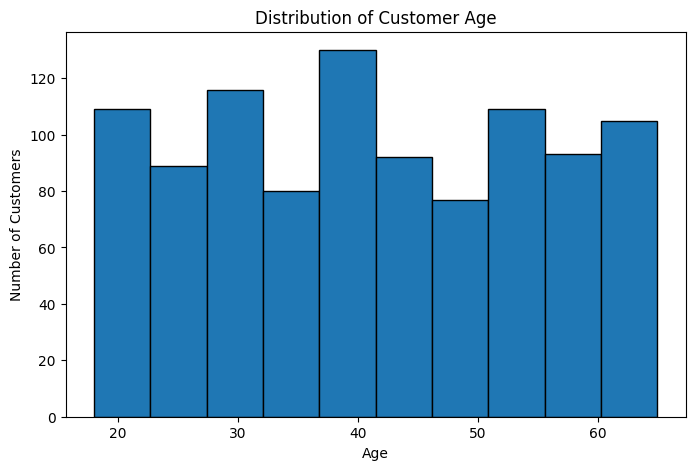

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(df['Age'], bins=10, edgecolor='black')

plt.title('Distribution of Customer Age')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.show()

In [ ]:
# Count the number of orders for each product

product_counts = df['Product'].value_counts()

print(product_counts)

Product
Mobile    184
Book      178
Laptop    170
Chair     159
Shoes     156
Rice      153
Name: count, dtype: int64


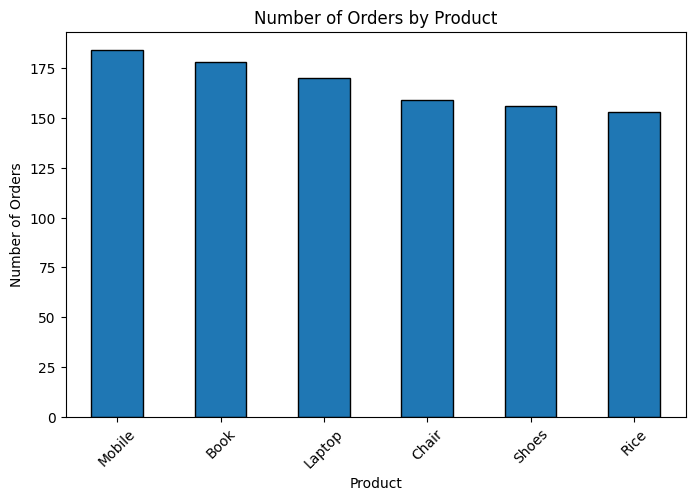

In [ ]:
plt.figure(figsize=(8, 5))

product_counts.plot(kind='bar', edgecolor='black')

plt.title('Number of Orders by Product')
plt.xlabel('Product')
plt.ylabel('Number of Orders')

plt.xticks(rotation=45)
plt.show()

In [ ]:
# Calculate product frequency
product_counts = df['Product'].value_counts()

# Calculate percentage distribution
product_percentage = df['Product'].value_counts(normalize=True) * 100

# Combine both into a DataFrame
product_analysis = pd.DataFrame({
    'Frequency': product_counts,
    'Percentage': product_percentage
})

print(product_analysis.round(2))

         Frequency  Percentage
Product                       
Mobile         184        18.4
Book           178        17.8
Laptop         170        17.0
Chair          159        15.9
Shoes          156        15.6
Rice           153        15.3


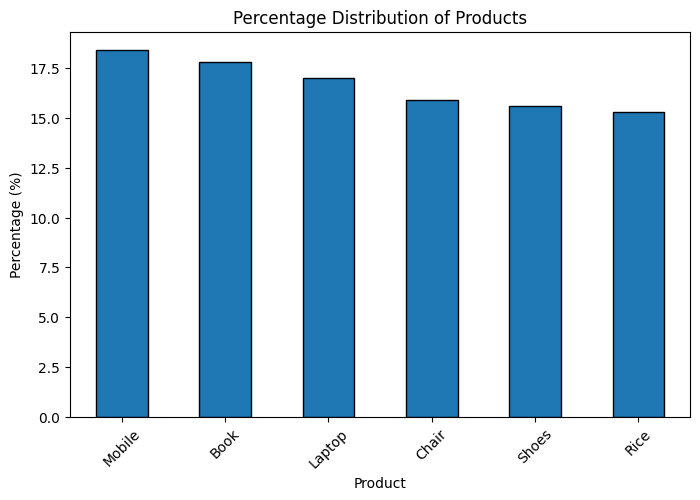

In [ ]:
plt.figure(figsize=(8, 5))

product_percentage.plot(kind='bar', edgecolor='black')

plt.title('Percentage Distribution of Products')
plt.xlabel('Product')
plt.ylabel('Percentage (%)')

plt.xticks(rotation=45)
plt.show()

Gender
Male      511
Female    489
Name: count, dtype: int64


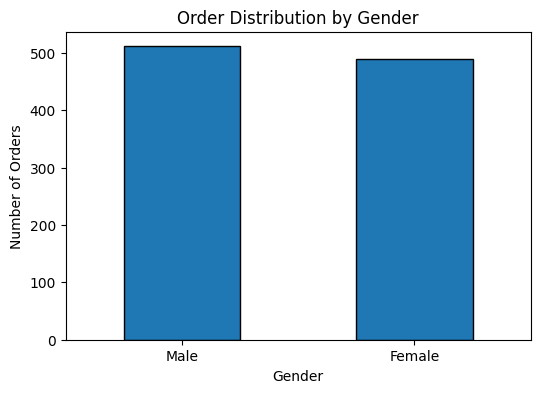

In [ ]:
# Count customers by gender
gender_counts = df['Gender'].value_counts()

print(gender_counts)
plt.figure(figsize=(6, 4))

gender_counts.plot(kind='bar', edgecolor='black')

plt.title('Order Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Orders')

plt.xticks(rotation=0)
plt.show()

In [ ]:
category_counts = df['Category'].value_counts()

print(category_counts)

Category
Electronics    354
Education      178
Furniture      159
Fashion        156
Grocery        153
Name: count, dtype: int64


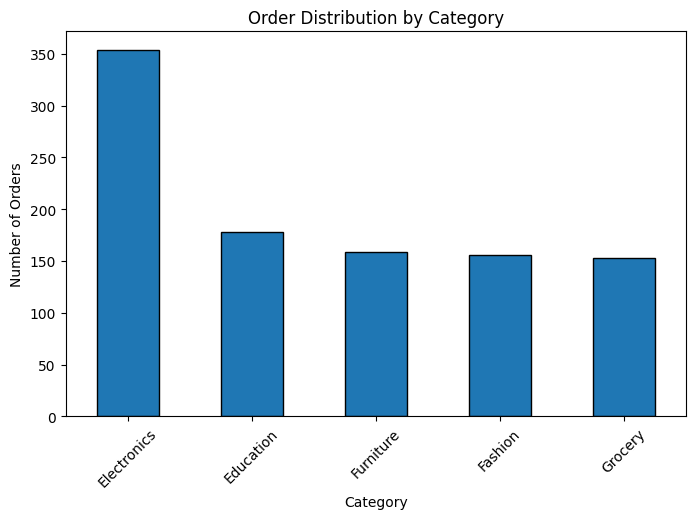

In [ ]:
plt.figure(figsize=(8, 5))

category_counts.plot(kind='bar', edgecolor='black')

plt.title('Order Distribution by Category')
plt.xlabel('Category')
plt.ylabel('Number of Orders')

plt.xticks(rotation=45)
plt.show()

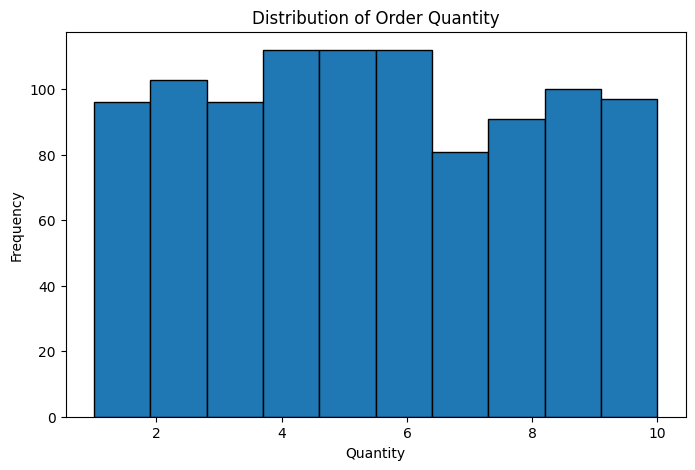

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(df['Quantity'], bins=10, edgecolor='black')

plt.title('Distribution of Order Quantity')
plt.xlabel('Quantity')
plt.ylabel('Frequency')

plt.show()

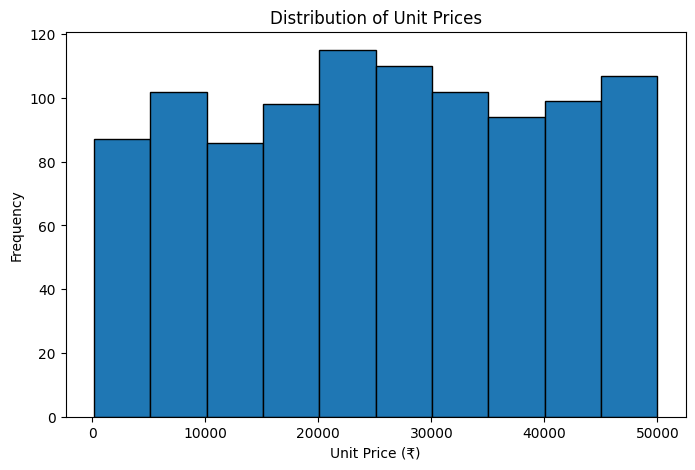

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(df['Unit_Price'], bins=10, edgecolor='black')

plt.title('Distribution of Unit Prices')
plt.xlabel('Unit Price (₹)')
plt.ylabel('Frequency')

plt.show()

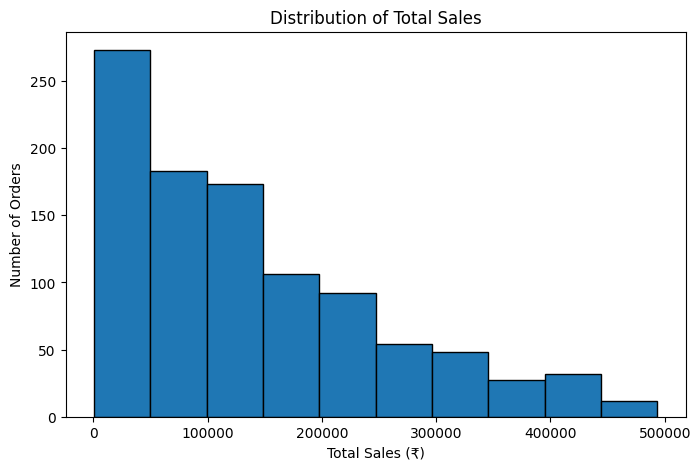

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(df['Total_Sales'], bins=10, edgecolor='black')

plt.title('Distribution of Total Sales')
plt.xlabel('Total Sales (₹)')
plt.ylabel('Number of Orders')

plt.show()

In [ ]:
city_counts = df['City'].value_counts()

print(city_counts)

City
Patna        135
Kolkata      133
Mumbai       131
Delhi        125
Hyderabad    125
Bengaluru    122
Gaya         117
Pune          99
Unknown       13
Name: count, dtype: int64


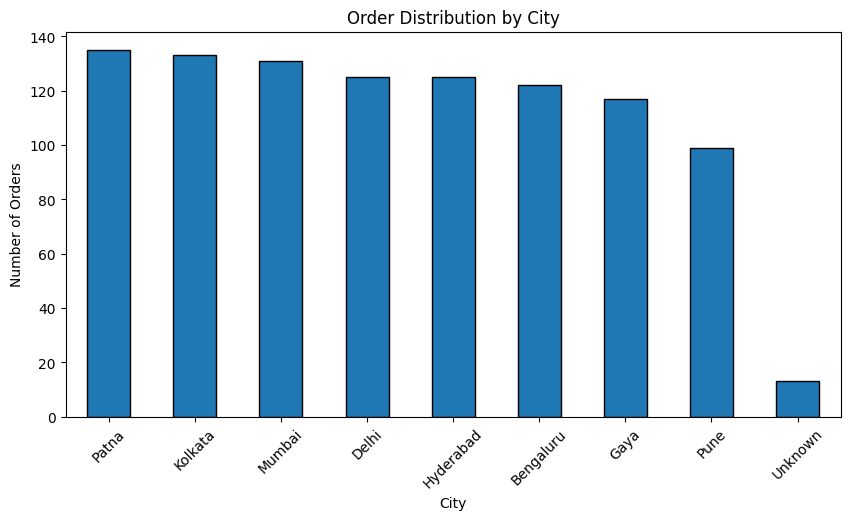

In [ ]:
plt.figure(figsize=(10, 5))

city_counts.plot(kind='bar', edgecolor='black')

plt.title('Order Distribution by City')
plt.xlabel('City')
plt.ylabel('Number of Orders')

plt.xticks(rotation=45)
plt.show()